In [1]:
def dp2_dia_objects(target, ra, dec, DIA_SEARCH_RADIUS_DEG=20):
    query = f"""
    SELECT diaObjectId, ra, dec
    FROM {DIA_OBJECT_TABLE}
    WHERE CONTAINS(
        POINT('ICRS', ra, dec),
        CIRCLE('ICRS', {ra:.15g}, {dec:.15g}, {DIA_SEARCH_RADIUS_DEG:.15g})
    ) = 1
    """
    dia_job = tap_service.submit_job(query)
    dia_job.run()
    dia_job.wait(phases=["COMPLETED", "ERROR"])
    if dia_job.phase == "ERROR":
        dia_job.raise_if_error()
    objects = dia_job.fetch_result().to_table().to_pandas()
    return objects

In [18]:
import pandas as pd
CSV_PATH = "ogle_test_matchs.csv"
CSV_PATH = "lastberuXdp2_coords.csv"
targets = pd.read_csv(CSV_PATH)
targets.columns = targets.columns.astype(str).str.strip()

print(f"Targets loaded: {len(targets)}")
targets.head()


Targets loaded: 2324


,object_id,ra,dec,coord_ra,coord_dec
0,LaStBeRu_J014341.5+194553.4,25.92287,19.76483,25.922936,19.764723
1,LaStBeRu_J013732.6+210924.3,24.38567,21.15675,24.385600,21.156802
2,LaStBeRu_J014230.1+211832.9,25.62550,21.30912,25.625478,21.309121
3,LaStBeRu_J233356.1-142304.6,353.48358,-14.38460,353.483548,-14.384629
4,LaStBeRu_J232833.1-143453.8,352.13779,-14.58160,352.137848,-14.581657


In [13]:
from astropy.coordinates import SkyCoord
import astropy.units as u
from lsst.rsp import get_tap_service
tap_service = get_tap_service("tap")
DIA_OBJECT_TABLE = "dp2.DiaObject"
DIA_SEARCH_RADIUS_ARCSEC = 20.0
DIA_SEARCH_RADIUS_DEG = DIA_SEARCH_RADIUS_ARCSEC / 3600.0

nearest_rows = []

for target in targets.itertuples(index=False):
    #target_name = target.target_id
    target_name = target.object_id
    ra = target.coord_ra
    dec = target.coord_dec
    query = f"""
    SELECT diaObjectId, ra, dec
    FROM {DIA_OBJECT_TABLE}
    WHERE CONTAINS(
        POINT('ICRS', ra, dec),
        CIRCLE('ICRS', {target.coord_ra:.15g}, {target.coord_dec:.15g}, {DIA_SEARCH_RADIUS_DEG:.15g})
    ) = 1
    """
    dia_job = tap_service.submit_job(query)
    dia_job.run()
    dia_job.wait(phases=["COMPLETED", "ERROR"])
    if dia_job.phase == "ERROR":
        dia_job.raise_if_error()
    objects = dia_job.fetch_result().to_table().to_pandas()
    break
objects

,diaObjectId,ra,dec
0,751857802103754732,266.791435,-32.527370
1,751857802103754733,266.794044,-32.525438
2,751857802103754705,266.792762,-32.522843
3,751857802103754714,266.794645,-32.523004
4,751857802103754781,266.798018,-32.528919
5,751857802103754772,266.793542,-32.530862
6,751857802103754777,266.794729,-32.530574
7,751857802103754778,266.798578,-32.528001
8,751857802103752239,266.790702,-32.530147
9,751857802103752253,266.794734,-32.526660


In [4]:
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.visualization import ImageNormalize,AsinhStretch
from lsst.daf.butler import Butler
coord = SkyCoord(ra * u.deg, dec * u.deg)
butler = Butler("dp2", collections="dp2")
fig = plt.figure(figsize=(18, 10))
for index, band in enumerate("ugrizy", start=1):
  refs = list(
      butler.query_datasets(
          "deep_coadd",
          where="patch.region OVERLAPS POINT(:ra, :dec)",
          bind={"ra": ra, "dec": dec},
      )
  )

  selected = None

  for ref in refs:
      if str(ref.dataId.get("band", "")) != band:
          continue

      coadd = butler.get(ref)
      wcs = coadd.fits_wcs
      x, y = wcs.world_to_pixel(coord)

      height, width = coadd.image.array.shape

      if 0 <= x < width and 0 <= y < height:
          selected = (coadd, wcs, x, y)
          break

  ax = fig.add_subplot(2, 3, index, projection=selected[1]
  if selected else None)

  if selected is None:
      ax.text(
          0.5, 0.5,
          f"No DP2 coadd in {band}",
          ha="center",
          va="center",
          transform=ax.transAxes,
      )
      ax.set_title(f"{band} band")
      ax.axis("off")
      continue

  coadd, wcs, x, y = selected
  image = np.asarray(coadd.image.array, dtype=float)
  finite = image[np.isfinite(image)]
    
  vmin, vmax = np.percentile(finite, [5, 99.5])
  norm = ImageNormalize(
      vmin=vmin,
      vmax=vmax,
      stretch=AsinhStretch(0.08),
      clip=True,
  )
  ax.imshow(image,origin="lower",cmap="gray",norm=norm)
  ax.plot(x, y, "o", color="red", ms=6, mfc="none",
  mew=1.5)
  ax.set_title(f"{target_name} — DP2 {band}")
  ax.coords[0].set_axislabel("RA")
  ax.coords[1].set_axislabel("Dec")
  # for i, row in objects.iterrows():
  #     coord_det = SkyCoord(row.ra * u.deg, row.dec * u.deg)
  #     x, y = wcs.world_to_pixel(coord_det)
  #     ax.plot(x, y, "o", color="cyan", ms=6, mfc="none",
  #     mew=1.5)

plt.tight_layout()
plt.show()

KeyboardInterrupt: 

Error in callback <function flush_figures at 0x7dcbe7ce7600> (for post_execute), with arguments args (),kwargs {}:


KeyboardInterrupt: 

Radio: 20" | DiaObjects encontrados: 25
           diaObjectId  sep_arcsec
9   751857802103752253    0.126650
1   751857802103754733    4.748224
23  751857802103756658    6.986776
11  751857802103752950    7.305994
15  751857802103752518    9.022799
19  751857802103757242   10.062013
0   751857802103754732   10.286912
21  751857802103757771   10.869961
7   751857802103754778   12.736303
4   751857802103754781   12.986115
12  751857802103752953   12.996878
3   751857802103754714   13.063443
14  751857802103752514   13.939084
6   751857802103754777   14.191647
20  751857802103757768   14.280981
10  751857802103751591   14.334022
24  751857802103756654   14.736049
2   751857802103754705   14.865397
17  751857802103752536   15.601155
5   751857802103754772   15.634189
13  751857802103753347   16.390881
8   751857802103752239   17.552491
22  751857802103756671   18.273125
18  751857802103757243   18.698107
16  751857802103752522   19.644524


/tmp/ipykernel_44181/4023094272.py:68: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.show()


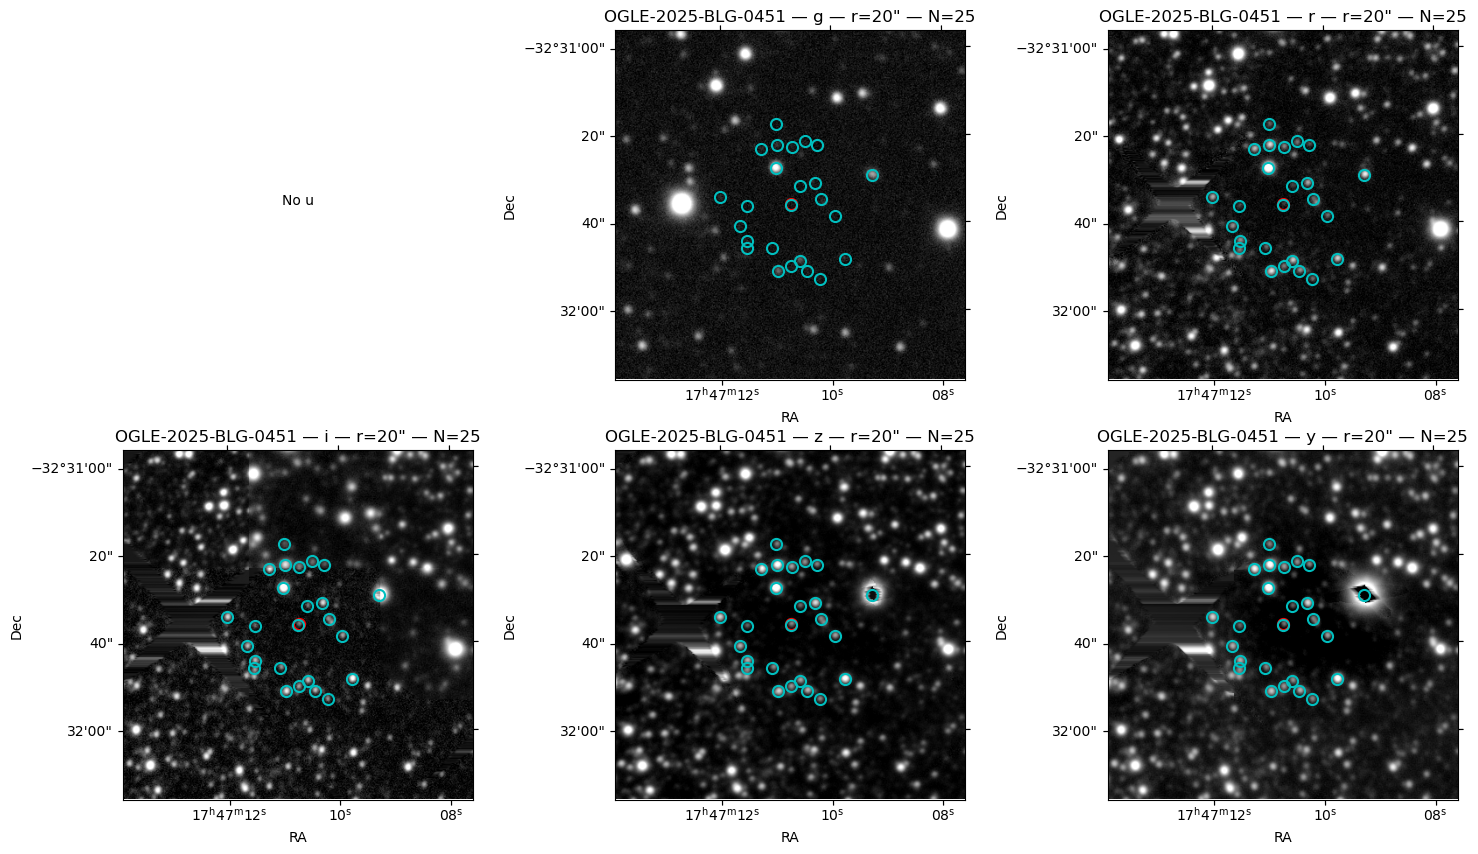

In [15]:
import numpy as np, matplotlib.pyplot as plt, astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.visualization import ImageNormalize, AsinhStretch
from astropy.wcs.utils import proj_plane_pixel_scales
from lsst.daf.butler import Butler

target_name="OGLE-2025-BLG-0451"; ra_deg,dec_deg=ra, dec
cutout_size_arcsec=80
search_radius_arcsec=20  # →
radius_deg=search_radius_arcsec/3600

coord=SkyCoord(ra_deg*u.deg,dec_deg*u.deg)
butler=Butler("dp2",collections="dp2")
fig=plt.figure(figsize=(18,10))

query=f"""
SELECT diaObjectId,ra,dec
FROM {DIA_OBJECT_TABLE}
WHERE CONTAINS(
POINT('ICRS',ra,dec),
CIRCLE('ICRS',{ra_deg:.15g},{dec_deg:.15g},{radius_deg:.15g})
)=1
"""
dia_job=tap_service.submit_job(query); dia_job.run(); dia_job.wait(phases=["COMPLETED","ERROR"])
if dia_job.phase=="ERROR": dia_job.raise_if_error()
objects=dia_job.fetch_result().to_table().to_pandas()

if len(objects)>0:
    objcoords=SkyCoord(objects.ra.values*u.deg,objects.dec.values*u.deg)
    objects["sep_arcsec"]=coord.separation(objcoords).arcsec

print(f"Radio: {search_radius_arcsec}\" | DiaObjects encontrados: {len(objects)}")
if len(objects)>0: print(objects[["diaObjectId","sep_arcsec"]].sort_values("sep_arcsec"))

refs=list(butler.query_datasets("deep_coadd",where="patch.region OVERLAPS POINT(:ra,:dec)",bind={"ra":ra_deg,"dec":dec_deg}))

for i,band in enumerate("ugrizy",1):
    sel=None
    for ref in refs:
        if str(ref.dataId.get("band",""))!=band: continue
        coadd=butler.get(ref); wcs=coadd.fits_wcs
        x,y=wcs.world_to_pixel(coord); img=np.asarray(coadd.image.array,float); h,w=img.shape
        if 0<=x<w and 0<=y<h: sel=(wcs,x,y,img,h,w); break

    if sel is None:
        ax=fig.add_subplot(2,3,i); ax.text(.5,.5,f"No {band}",ha="center"); ax.axis("off"); continue

    wcs,x,y,img,h,w=sel
    pixscale=np.mean(proj_plane_pixel_scales(wcs))*3600
    hs=int((cutout_size_arcsec/pixscale)/2)
    x0,x1=max(0,int(x)-hs),min(w,int(x)+hs); y0,y1=max(0,int(y)-hs),min(h,int(y)+hs)
    cut=img[y0:y1,x0:x1]; f=cut[np.isfinite(cut)]
    if len(f)==0: continue

    vmin,vmax=np.percentile(f,[5,99.5])
    ax=fig.add_subplot(2,3,i,projection=wcs)
    ax.imshow(cut,origin="lower",cmap="gray",extent=[x0,x1,y0,y1],norm=ImageNormalize(vmin=vmin,vmax=vmax,stretch=AsinhStretch(.08)))
    ax.plot(x,y,"ro",ms=8,mfc="none",mew=1.5)

    for _,row in objects.iterrows():
        xd,yd=wcs.world_to_pixel(SkyCoord(row.ra*u.deg,row.dec*u.deg))
        ax.plot(xd,yd,"co",ms=8,mfc="none",mew=1.5)

    ax.set_xlim(x0,x1); ax.set_ylim(y0,y1)
    ax.set_title(f"{target_name} — {band} — r={search_radius_arcsec}\" — N={len(objects)}")
    ax.coords[0].set_axislabel("RA"); ax.coords[1].set_axislabel("Dec")

plt.tight_layout(); plt.show()

## Cone search every match for StrongLensing

In [23]:
from astropy.coordinates import SkyCoord
import astropy.units as u
from lsst.rsp import get_tap_service
import pandas as pd
import pickle
from tqdm import tqdm

tap_service = get_tap_service("tap")

DIA_OBJECT_TABLE = "dp2.DiaObject"
DIA_SEARCH_RADIUS_ARCSEC = 20.0
DIA_SEARCH_RADIUS_DEG = DIA_SEARCH_RADIUS_ARCSEC / 3600.0

CSV_PATH = "lastberuXdp2_coords.csv"
PICKLE_PATH = "lastberu_dia_objects.pkl"

targets = pd.read_csv(CSV_PATH)
targets.columns = targets.columns.astype(str).str.strip()

print(f"Targets loaded: {len(targets)}")

objects_by_target = {}
for target in tqdm(targets.itertuples(index=False), total=len(targets)):
   #target_name = target.target_id
    target_name = target.object_id
    ra = target.coord_ra
    dec = target.coord_dec
    query = f"""
    SELECT diaObjectId, ra, dec
    FROM {DIA_OBJECT_TABLE}
    WHERE CONTAINS(
        POINT('ICRS', ra, dec),
        CIRCLE(
            'ICRS',
            {ra:.15g},
            {dec:.15g},
            {DIA_SEARCH_RADIUS_DEG:.15g}
        )
    ) = 1
    """

    dia_job = tap_service.submit_job(query)
    dia_job.run()
    dia_job.wait(phases=["COMPLETED", "ERROR"])

    if dia_job.phase == "ERROR":
        dia_job.raise_if_error()

    objects = dia_job.fetch_result().to_table().to_pandas()
    objects_by_target[target_name] = objects
    #print(f"{target_name}: find {len(objects)} DiaObjects")

with open(PICKLE_PATH, "wb") as f:
    pickle.dump(objects_by_target, f)

print(f"Saved in {PICKLE_PATH}")

Targets loaded: 2324


 59%|█████▉    | 1382/2324 [1:17:46<53:01,  3.38s/it]  


KeyboardInterrupt: 